# 02 — Làm sạch dữ liệu trước tạo đặc trưng

Notebook độc lập, không gọi `src/`. Đọc tám bảng từ `data/interim/`, tái sử dụng
`train/val` và fold của notebook 01; xuất bảng đã làm sạch vào `data/processed/`.
Báo cáo CSV cấu hình ở `reports/tables/`. Không sửa raw, interim hoặc split.

**Các phần chính**
1. Kiểm tra nguồn và phân chia đã cố định.
2. Công bố quy tắc làm sạch và các vấn đề chỉ ghi nhận.
3. Làm sạch từng bảng, đối chiếu trước/sau và ghi audit.
4. Kiểm tra orphan, chủ sở hữu khoản vay và bản ghi thanh toán lặp.
5. Kiểm tra kết quả lưu, bàn giao cho notebook tạo đặc trưng.

Không fit imputation, scaling, encoding, chọn đặc trưng hoặc huấn luyện.
Quy tắc là cố định theo ý nghĩa cột, không học từ phân phối holdout; báo cáo chất lượng
toàn bộ bảng không được dùng để tuning. Không cắt outlier theo quantile hay đổi dấu toàn bộ cột DAYS.


## 1. Thiết lập và kiểm tra đầu vào
Dùng môi trường của dự án. Chạy notebook 01 trước để có Parquet và split; notebook này không tạo lại split.


In [1]:
import hashlib
import json
from datetime import datetime, timezone
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display

def locate_project_root(cwd: Path) -> Path:
    override = os.getenv("HOME_CREDIT_ROOT")
    if override:
        root = Path(override).expanduser().resolve()
        if not (root / "data" / "raw").is_dir():
            raise FileNotFoundError(f"HOME_CREDIT_ROOT không chứa data/raw/: {root}")
        return root
    for folder in (cwd.resolve(), *cwd.resolve().parents):
        if (folder / "data" / "raw").is_dir():
            return folder
    raise FileNotFoundError("Không tìm thấy data/raw/. Đặt HOME_CREDIT_ROOT.")

ROOT = locate_project_root(Path.cwd())
INTERIM_DIR = ROOT / "data" / "interim"
PROCESSED_DIR = ROOT / "data" / "processed"
SPLIT_DIR = ROOT / "data" / "splits"
REPORT_DIR = ROOT / "reports" / "tables"
TABLES = ["application_train", "application_test", "bureau", "bureau_balance",
          "previous_application", "POS_CASH_balance", "installments_payments", "credit_card_balance"]
ID_COL, TARGET_COL = "SK_ID_CURR", "TARGET"
EXPORT_REPORTS = True  # False để kiểm tra mà không ghi reports/.
RULE_VERSION = "cleaning_v1"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 18)
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 110})


def save_report(frame: pd.DataFrame, name: str) -> None:
    if EXPORT_REPORTS:
        REPORT_DIR.mkdir(parents=True, exist_ok=True)
        frame.to_csv(REPORT_DIR / name, index=False, encoding="utf-8-sig")


def file_sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


required = [INTERIM_DIR / f"{t}.parquet" for t in TABLES]
required += [SPLIT_DIR / p for p in ["train.parquet", "val.parquet", "train_val_metadata.json"]]
missing = [str(p) for p in required if not p.is_file()]
if missing:
    raise FileNotFoundError(f"Thiếu đầu vào từ notebook 01: {missing}")
split_hashes_before = {p.name: file_sha256(p) for p in required[-3:]}
print(f"Root: {ROOT}; đầu vào: {len(TABLES)} bảng; output: {PROCESSED_DIR}")


Root: D:\HCMUT\(HK261_CQ) LẬP TRÌNH CHO TRÍ TUỆ NHÂN TẠO VÀ KHOA HỌC DỮ LIỆU (CO3135)_TRẦN HUY\home-credit-risk; đầu vào: 8 bảng; output: D:\HCMUT\(HK261_CQ) LẬP TRÌNH CHO TRÍ TUỆ NHÂN TẠO VÀ KHOA HỌC DỮ LIỆU (CO3135)_TRẦN HUY\home-credit-risk\data\processed


In [2]:
def labeled_source_sha256(df: pd.DataFrame) -> str:
    array = df.sort_values(ID_COL)[[ID_COL, TARGET_COL]].to_numpy(dtype="int64")
    return hashlib.sha256(np.ascontiguousarray(array).tobytes()).hexdigest()

labels = pd.read_parquet(INTERIM_DIR / "application_train.parquet", columns=[ID_COL, TARGET_COL])
train_split = pd.read_parquet(SPLIT_DIR / "train.parquet")
val_split = pd.read_parquet(SPLIT_DIR / "val.parquet")
split_metadata = json.loads((SPLIT_DIR / "train_val_metadata.json").read_text(encoding="utf-8"))
assert labels.notna().all().all() and labels[ID_COL].is_unique
assert set(labels[TARGET_COL].unique()) == {0, 1}
assert labeled_source_sha256(labels) == split_metadata["source_sha256"]
assert list(train_split.columns) == [ID_COL, "fold"] and list(val_split.columns) == [ID_COL]
assert train_split.notna().all().all() and val_split.notna().all().all()
assert train_split[ID_COL].is_unique and val_split[ID_COL].is_unique
assert not set(train_split[ID_COL]) & set(val_split[ID_COL])
assert set(train_split[ID_COL]) | set(val_split[ID_COL]) == set(labels[ID_COL])
assert set(train_split.fold) == set(range(5))
assert abs(len(val_split) / len(labels) - 0.2) <= 1 / len(labels)
test_ids = pd.read_parquet(INTERIM_DIR / "application_test.parquet", columns=[ID_COL])
assert test_ids[ID_COL].notna().all() and test_ids[ID_COL].is_unique
assert not test_ids[ID_COL].isin(labels[ID_COL]).any()
print(f"Giữ nguyên train={len(train_split):,}, val={len(val_split):,}, 5 fold.")


Giữ nguyên train=246,008, val=61,503, 5 fold.


## 2. Quy tắc xử lý

| Vấn đề | Hành động |
|---|---|
| Khoảng trắng đầu/cuối chuỗi | Trim; chuỗi rỗng sau trim → missing |
| DAYS_EMPLOYED = 365243 ở application | → missing, không đổi các giá trị ngày khác |
| 365243 trong 5 cột mốc vay previous_application | → missing, không đổi giá trị ngày dương còn lại |
| CODE_GENDER = XNA ở application | → missing |
| ±inf ở cột float không phải khóa/TARGET | → missing |
| XNA/XAP ở cột khác; STATUS = X ở bureau_balance | Giữ nguyên vì có thể mang ý nghĩa riêng theo cột |
| Số 0, số âm, giá trị ngoài miền | Chỉ ghi nhận theo quy tắc cột; không tự sửa |
| Orphan hoặc bản ghi trùng | Giữ nguyên, báo cáo theo quan hệ và cấp độ bản ghi |

365243 tương đương khoảng 1.000 năm, được coi là sentinel ở đúng các cột liệt kê.
Đây là giả định làm sạch công khai; không áp dụng cho mọi cột DAYS. Ngày đến hạn trong
previous_application có thể nằm sau thời điểm hồ sơ hiện tại, nên dấu dương tự nó không phải lỗi.
Không thay đồng loạt XNA/XAP hay số 0 thành missing.

Audit ghi cả các quy tắc không tác động dòng nào. Một ô có thể đi qua trim rồi empty-to-missing,
vì vậy tổng `n_affected` giữa các quy tắc không phải số ô thay đổi duy nhất.


In [3]:
SENTINEL_COLUMNS = {
    "application_train": ["DAYS_EMPLOYED"],
    "application_test": ["DAYS_EMPLOYED"],
    "previous_application": ["DAYS_FIRST_DRAWING", "DAYS_FIRST_DUE", "DAYS_LAST_DUE_1ST_VERSION",
                             "DAYS_LAST_DUE", "DAYS_TERMINATION"],
}
RULE_SPEC = {"version": RULE_VERSION, "trim_strings": True, "empty_to_missing": True,
             "sentinel_value": 365243, "sentinel_columns": SENTINEL_COLUMNS,
             "gender_unknown_to_missing": "XNA", "nonfinite_float_to_missing": True,
             "preserve_rows_keys_target": True}
RULE_SIGNATURE = hashlib.sha256(json.dumps(RULE_SPEC, sort_keys=True).encode()).hexdigest()


def clean_table(df: pd.DataFrame, table: str) -> tuple[pd.DataFrame, list[dict]]:
    cleaned = df.copy(deep=False)
    audit = []
    protected = [c for c in df.columns if c.startswith("SK_ID_") or c == TARGET_COL]

    def record(column: str, rule: str, mask: pd.Series) -> None:
        n = int(mask.fillna(False).sum())
        audit.append({"table": table, "column": column, "rule": rule,
                      "n_affected": n, "n_rows": len(df), "affected_rate": n / len(df) if len(df) else 0.0})

    for col in cleaned.select_dtypes(include=["object", "string"]).columns:
        if col in protected:
            continue
        source = cleaned[col]
        trimmed = source.map(lambda value: value.strip() if isinstance(value, str) else value)
        trim_mask = source.notna() & source.ne(trimmed)
        record(col, "trim_whitespace", trim_mask)
        blank = trimmed.eq("").fillna(False)
        record(col, "empty_string_to_missing", blank)
        if trim_mask.any() or blank.any():
            cleaned[col] = trimmed.mask(blank, pd.NA)
    for col in SENTINEL_COLUMNS.get(table, []):
        if col in cleaned:
            mask = cleaned[col].eq(365243)
            record(col, "sentinel_365243_to_missing", mask)
            cleaned[col] = cleaned[col].mask(mask)
    if table in {"application_train", "application_test"} and "CODE_GENDER" in cleaned:
        mask = cleaned.CODE_GENDER.eq("XNA")
        record("CODE_GENDER", "unknown_gender_XNA_to_missing", mask)
        cleaned["CODE_GENDER"] = cleaned.CODE_GENDER.mask(mask, pd.NA)
    for col in cleaned.select_dtypes(include=["floating"]).columns:
        if col in protected:
            continue
        mask = cleaned[col].isin([np.inf, -np.inf])
        record(col, "nonfinite_to_missing", mask)
        if mask.any():
            cleaned[col] = cleaned[col].mask(mask)
    assert df[protected].equals(cleaned[protected]), "Khóa hoặc TARGET bị thay đổi"
    assert len(df) == len(cleaned) and df.index.equals(cleaned.index)
    assert list(df.columns) == list(cleaned.columns)
    return cleaned, audit


### 2.1. Kiểm tra ngoài miền: chỉ báo cáo
Kiểm tra các miền rõ ràng: giờ 0–23, EXT_SOURCE trong [0,1], số đếm và DPD không âm,
application có tuổi tính bằng ngày âm và một số khoản tiền phải dương.
Giá trị âm ở các khoản tiền khác được gắn cờ xem xét, không coi mặc định là dữ liệu hỏng
(ví dụ số dư có thể có điều chỉnh). Các cột RATE không bị ép về [0,1].


In [4]:
def review_domains(df: pd.DataFrame, table: str) -> list[dict]:
    rows = []

    def record(col: str, rule: str, mask: pd.Series) -> None:
        n = int(mask.fillna(False).sum())
        rows.append({"table": table, "column": col, "rule": rule, "n_affected": n,
                     "n_rows": len(df), "affected_rate": n / len(df) if len(df) else 0.0,
                     "action": "review_only_preserve_value"})

    for col in df.columns:
        s = df[col]
        if pd.api.types.is_numeric_dtype(s):
            if col.startswith("CNT_") or col in {"SK_DPD", "SK_DPD_DEF", "CREDIT_DAY_OVERDUE"}:
                record(col, "negative_count_or_dpd", s.lt(0))
                record(col, "fractional_count_or_dpd", s.notna() & s.mod(1).ne(0))
            if col.startswith("AMT_"):
                record(col, "negative_amount_review", s.lt(0))
            if col == "HOUR_APPR_PROCESS_START":
                record(col, "hour_outside_0_23", s.notna() & (s.lt(0) | s.gt(23) | s.mod(1).ne(0)))
            if col.startswith("EXT_SOURCE_"):
                record(col, "external_score_outside_0_1", s.lt(0) | s.gt(1))
            if col == "MONTHS_BALANCE":
                record(col, "positive_history_month_review", s.gt(0))
        else:
            for marker in ("XNA", "XAP"):
                record(col, f"retained_literal_{marker}", s.eq(marker))
    if table.startswith("application_"):
        for col in ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]:
            if col in df:
                record(col, "nonpositive_application_amount_review", df[col].le(0))
        for col in ["DAYS_BIRTH", "DAYS_EMPLOYED", "DAYS_REGISTRATION", "DAYS_ID_PUBLISH", "DAYS_LAST_PHONE_CHANGE"]:
            if col in df:
                mask = df[col].ge(0) if col == "DAYS_BIRTH" else df[col].gt(0)
                record(col, "unexpected_application_day_sign_review", mask)
        if "CODE_GENDER" in df:
            record("CODE_GENDER", "unrecognized_gender_review", df.CODE_GENDER.notna() & ~df.CODE_GENDER.isin(["F", "M"]))
    if table == "bureau_balance" and "STATUS" in df:
        record("STATUS", "unrecognized_bureau_status_review", df.STATUS.notna() & ~df.STATUS.isin(["0", "1", "2", "3", "4", "5", "C", "X"]))
    return rows


## 3. Làm sạch và kiểm tra trước/sau từng bảng
Mỗi vòng giữ một bảng nguồn và bản làm sạch, không nạp tất cả bảng lịch sử cùng lúc.
Giữ số hàng, thứ tự, tên cột, khóa và TARGET; duplicate toàn dòng có thể tăng sau chuẩn hóa,
nên được đo cả trước lẫn sau và không tự loại bỏ.

Dừng nếu fingerprint trong manifest không khớp. Output đã có, kể cả file chưa kịp ghi manifest
sau gián đoạn, chỉ được tái sử dụng khi đối soát toàn bộ nội dung theo batch với kết quả làm sạch
từ nguồn. Không tự ghi đè output. Manifest cập nhật sau mỗi bảng đã xác minh để có thể chạy tiếp.
Fingerprint của nguồn, file đầu ra và quy tắc được lưu trong `data/processed/cleaning_manifest.json`.


In [5]:
manifest_path = PROCESSED_DIR / "cleaning_manifest.json"
output_paths = [PROCESSED_DIR / f"{table}.parquet" for table in TABLES]
existing_outputs = [path.exists() for path in output_paths]
reuse = manifest_path.exists()
if reuse:
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    assert manifest["rule_signature"] == RULE_SIGNATURE, "Quy tắc khác với output cũ"
    assert set(manifest["tables"]).issubset(TABLES), "Manifest chứa bảng ngoài phạm vi"
    assert all((PROCESSED_DIR / f"{t}.parquet").is_file() for t in manifest["tables"]), "Thiếu output trong manifest"
else:
    manifest = {"rule_signature": RULE_SIGNATURE, "rules": RULE_SPEC,
                "created_at_utc": datetime.now(timezone.utc).isoformat(), "tables": {}}

# Preflight toàn bộ nguồn/output trước khi bắt đầu ghi.
source_hashes = {}
for table in TABLES:
    source_hashes[table] = file_sha256(INTERIM_DIR / f"{table}.parquet")
    if table in manifest["tables"]:
        entry = manifest["tables"][table]
        assert entry["source_sha256"] == source_hashes[table], f"Nguồn thay đổi: {table}"
        assert entry["output_sha256"] == file_sha256(PROCESSED_DIR / f"{table}.parquet"), f"Output thay đổi: {table}"
print("Output đã có được đối soát toàn bộ nội dung theo batch; file chưa có sẽ được tạo mới.")


Output đã có được đối soát toàn bộ nội dung theo batch; file chưa có sẽ được tạo mới.


In [6]:
summary_rows, column_rows, audit_rows, review_rows = [], [], [], []
for table in TABLES:
    source = pd.read_parquet(INTERIM_DIR / f"{table}.parquet")
    cleaned, audit = clean_table(source, table)
    audit_rows.extend(audit)
    review_rows.extend(review_domains(cleaned, table))
    protected = [c for c in source if c.startswith("SK_ID_") or c == TARGET_COL]
    assert source[protected].equals(cleaned[protected])
    assert list(source.columns) == list(cleaned.columns) and len(source) == len(cleaned)
    missing_before, missing_after = source.isna().sum(), cleaned.isna().sum()
    assert missing_after.ge(missing_before).all(), "Không được điền thiếu trong notebook này"
    n_changed_total = 0
    for col in source:
        unchanged = source[col].eq(cleaned[col]).fillna(False) | (source[col].isna() & cleaned[col].isna())
        changed = int((~unchanged).sum())
        n_changed_total += changed
        column_rows.append({"table": table, "column": col,
                            "dtype_before": str(source[col].dtype), "dtype_after": str(cleaned[col].dtype),
                            "n_missing_before": int(missing_before[col]), "n_missing_after": int(missing_after[col]),
                            "n_missing_added": int(missing_after[col] - missing_before[col]), "n_changed_cells": changed})
    destination = PROCESSED_DIR / f"{table}.parquet"
    existed = destination.exists()
    if not existed:
        temporary = destination.with_suffix(".parquet.inprogress")
        if temporary.exists():
            raise FileExistsError(f"Có output chưa hoàn tất: {temporary}")
        cleaned.to_parquet(temporary, engine="pyarrow", compression="snappy", index=False)
        temporary.rename(destination)
    # Đọc lại output, kiểm tra dữ liệu và dtype chứ không chỉ số hàng.
    saved_rows = 0
    with pq.ParquetFile(destination) as reader:
        assert reader.schema_arrow.names == list(cleaned.columns)
        for batch in reader.iter_batches(batch_size=65_536):
            saved_batch = batch.to_pandas()
            expected_batch = cleaned.iloc[saved_rows:saved_rows + len(saved_batch)].reset_index(drop=True)
            pd.testing.assert_frame_equal(saved_batch, expected_batch, check_dtype=True)
            saved_rows += len(saved_batch)
        assert saved_rows == len(cleaned)
    del saved_batch, expected_batch
    duplicates_before = int(source.duplicated().sum())
    duplicates_after = duplicates_before if n_changed_total == 0 else int(cleaned.duplicated().sum())
    summary_rows.append({"table": table, "n_rows_before": len(source), "n_rows_after": len(cleaned),
                         "n_columns": len(cleaned.columns), "n_changed_cells": n_changed_total,
                         "n_missing_before": int(missing_before.sum()), "n_missing_after": int(missing_after.sum()),
                         "n_duplicate_rows_before": duplicates_before,
                         "n_duplicate_rows_after": duplicates_after,
                         "protected_columns_unchanged": True, "saved_content_verified": True,
                         "status": "reused_verified" if existed else "created"})
    manifest["tables"][table] = {"source_sha256": source_hashes[table],
                                 "output_sha256": file_sha256(destination), "n_rows": len(cleaned),
                                 "columns": list(cleaned.columns)}
    print(f"[VERIFIED] {table}: {len(cleaned):,} hàng; {n_changed_total:,} ô thay đổi", flush=True)
    manifest_path.write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
    del source, cleaned
cleaning_summary_df = pd.DataFrame(summary_rows)
cleaning_columns_df = pd.DataFrame(column_rows)
cleaning_audit_df = pd.DataFrame(audit_rows)
domain_review_df = pd.DataFrame(review_rows)
save_report(cleaning_summary_df, "cleaning_summary.csv")
save_report(cleaning_columns_df, "cleaning_columns.csv")
save_report(cleaning_audit_df, "cleaning_audit.csv")
save_report(domain_review_df, "cleaning_domain_review.csv")
display(cleaning_summary_df)
display(cleaning_audit_df.loc[cleaning_audit_df.n_affected.gt(0)].head(30))
display(domain_review_df.loc[domain_review_df.n_affected.gt(0)].head(30))


[VERIFIED] application_train: 307,511 hàng; 819,749 ô thay đổi
[VERIFIED] application_test: 48,744 hàng; 128,308 ô thay đổi
[VERIFIED] bureau: 1,716,428 hàng; 0 ô thay đổi
[VERIFIED] bureau_balance: 27,299,925 hàng; 0 ô thay đổi
[VERIFIED] previous_application: 1,670,214 hàng; 2,326,838 ô thay đổi
[VERIFIED] POS_CASH_balance: 10,001,358 hàng; 0 ô thay đổi
[VERIFIED] installments_payments: 13,605,401 hàng; 0 ô thay đổi
[VERIFIED] credit_card_balance: 3,840,312 hàng; 0 ô thay đổi


,table,n_rows_before,n_rows_after,n_columns,n_changed_cells,n_missing_before,n_missing_after,n_duplicate_rows_before,n_duplicate_rows_after,protected_columns_unchanged,saved_content_verified,status
0,application_train,307511,307511,122,819749,8388094,9207843,0,0,True,True,reused_verified
1,application_test,48744,48744,121,128308,1285385,1413693,0,0,True,True,reused_verified
2,bureau,1716428,1716428,17,0,3939947,3939947,0,0,True,True,reused_verified
3,bureau_balance,27299925,27299925,3,0,0,0,0,0,True,True,reused_verified
4,previous_application,1670214,1670214,37,2326838,10288585,12615423,0,0,True,True,reused_verified
5,POS_CASH_balance,10001358,10001358,8,0,52158,52158,0,0,True,True,reused_verified
6,installments_payments,13605401,13605401,8,0,5810,5810,0,0,True,True,reused_verified
7,credit_card_balance,3840312,3840312,23,0,5877356,5877356,0,0,True,True,reused_verified


,table,column,rule,n_affected,n_rows,affected_rate
9,application_train,NAME_TYPE_SUITE,empty_string_to_missing,1292,307511,0.004201
19,application_train,OCCUPATION_TYPE,empty_string_to_missing,96391,307511,0.313455
25,application_train,FONDKAPREMONT_MODE,empty_string_to_missing,210295,307511,0.683862
27,application_train,HOUSETYPE_MODE,empty_string_to_missing,154297,307511,0.501761
29,application_train,WALLSMATERIAL_MODE,empty_string_to_missing,156341,307511,0.508408
31,application_train,EMERGENCYSTATE_MODE,empty_string_to_missing,145755,307511,0.473983
32,application_train,DAYS_EMPLOYED,sentinel_365243_to_missing,55374,307511,0.180072
33,application_train,CODE_GENDER,unknown_gender_XNA_to_missing,4,307511,0.000013
109,application_test,NAME_TYPE_SUITE,empty_string_to_missing,911,48744,0.018689
119,application_test,OCCUPATION_TYPE,empty_string_to_missing,15605,48744,0.320142


,table,column,rule,n_affected,n_rows,affected_rate,action
31,application_train,ORGANIZATION_TYPE,retained_literal_XNA,55374,307511,1.800716e-01,review_only_preserve_value
91,application_test,ORGANIZATION_TYPE,retained_literal_XNA,9274,48744,1.902593e-01,review_only_preserve_value
130,bureau,AMT_CREDIT_SUM_DEBT,negative_amount_review,8418,1716428,4.904371e-03,review_only_preserve_value
131,bureau,AMT_CREDIT_SUM_LIMIT,negative_amount_review,351,1716428,2.044945e-04,review_only_preserve_value
140,previous_application,NAME_CONTRACT_TYPE,retained_literal_XNA,346,1670214,2.071591e-04,review_only_preserve_value
145,previous_application,AMT_DOWN_PAYMENT,negative_amount_review,2,1670214,1.197451e-06,review_only_preserve_value
152,previous_application,NAME_CASH_LOAN_PURPOSE,retained_literal_XNA,677918,1670214,4.058869e-01,review_only_preserve_value
153,previous_application,NAME_CASH_LOAN_PURPOSE,retained_literal_XAP,922661,1670214,5.524208e-01,review_only_preserve_value
156,previous_application,NAME_PAYMENT_TYPE,retained_literal_XNA,627384,1670214,3.756309e-01,review_only_preserve_value
158,previous_application,CODE_REJECT_REASON,retained_literal_XNA,5244,1670214,3.139717e-03,review_only_preserve_value


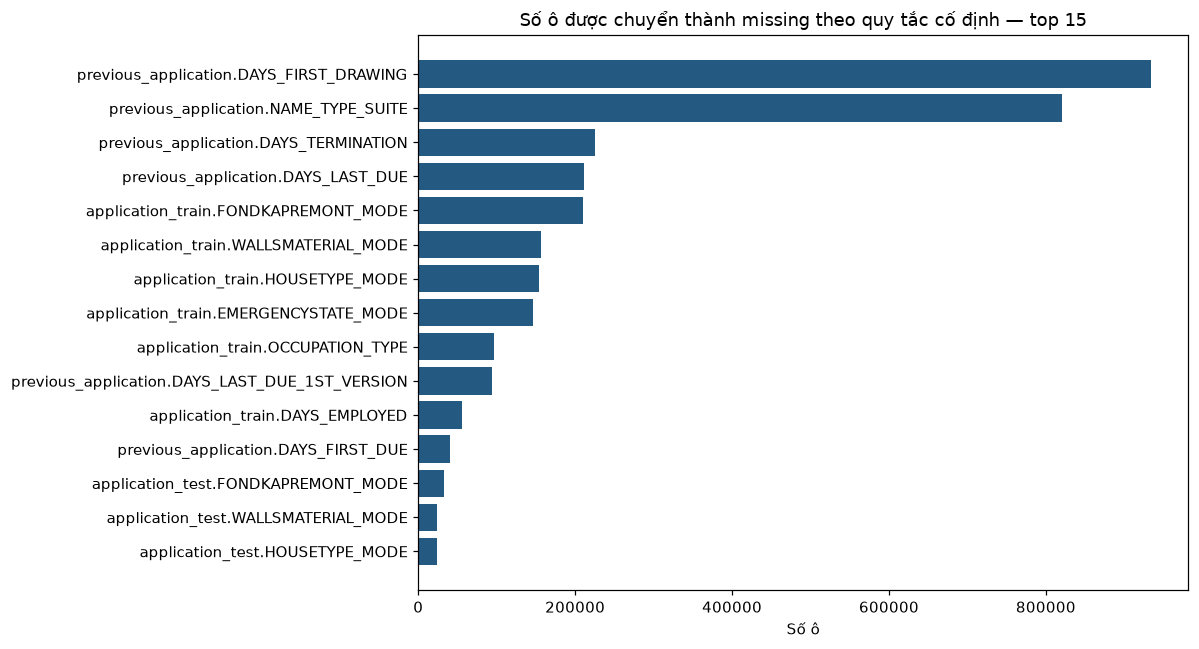

In [7]:
changed_columns = cleaning_columns_df.loc[cleaning_columns_df.n_missing_added.gt(0)].copy()
if not changed_columns.empty:
    changed_columns["label"] = changed_columns.table + "." + changed_columns.column
    plotted = changed_columns.nlargest(15, "n_missing_added").sort_values("n_missing_added")
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.barh(plotted.label, plotted.n_missing_added, color="#245A81")
    ax.set(title="Số ô được chuyển thành missing theo quy tắc cố định — top 15",
           xlabel="Số ô", ylabel="")
    ax.set_xlim(left=0)
    fig.tight_layout()
    plt.show()
else:
    print("Không có missing mới được thêm.")


## 4. Quan hệ và thanh toán trùng: giữ nguyên, báo cáo rõ

### 4.1. Khóa dự kiến sau làm sạch
Tái sử dụng định nghĩa kiểm tra từ notebook 01. Đây là kiểm tra NOT NULL + UNIQUE trên
bộ dữ liệu, không tự suy ra khóa chính nghiệp vụ. Với installments, một kỳ có thể có nhiều
lần thanh toán; tổ hợp kỳ trả không được dùng để loại trùng.


In [8]:
def check_candidate_key(df: pd.DataFrame, keys: list[str]) -> dict:
    if not keys or len(set(keys)) != len(keys) or not set(keys).issubset(df.columns):
        raise ValueError(f"Khóa không hợp lệ: {keys}")
    n_null = int(df[keys].isna().any(axis=1).sum())
    duplicates = df.duplicated(subset=keys, keep=False)
    return {
        "key_columns": " + ".join(keys), "n_rows": len(df),
        "n_null_key_rows": n_null,
        "n_duplicate_key_rows": int(duplicates.sum()),
        "n_duplicate_key_excess": int(df.duplicated(subset=keys).sum()),
        "passes_not_null_unique": bool(len(df) > 0 and n_null == 0 and not duplicates.any()),
        "duplicate_examples": json.dumps(df.loc[duplicates, keys].head(3).to_dict("records")),
    }

KEYS = {
    "application_train": [ID_COL], "application_test": [ID_COL], "bureau": ["SK_ID_BUREAU"],
    "bureau_balance": ["SK_ID_BUREAU", "MONTHS_BALANCE"], "previous_application": ["SK_ID_PREV"],
    "POS_CASH_balance": ["SK_ID_PREV", "MONTHS_BALANCE"],
    "credit_card_balance": ["SK_ID_PREV", "MONTHS_BALANCE"],
    "installments_payments": ["SK_ID_PREV", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER", "DAYS_ENTRY_PAYMENT", "AMT_PAYMENT"],
}
key_rows = []
for table, keys in KEYS.items():
    print(f"[KEY] {table}", flush=True)
    before = pd.read_parquet(INTERIM_DIR / f"{table}.parquet", columns=keys)
    result_before = check_candidate_key(before, keys)
    del before
    after = pd.read_parquet(PROCESSED_DIR / f"{table}.parquet", columns=keys)
    result_after = check_candidate_key(after, keys)
    assert result_before["n_null_key_rows"] == result_after["n_null_key_rows"]
    assert result_before["n_duplicate_key_excess"] == result_after["n_duplicate_key_excess"]
    key_rows.append({"table": table, "role": "diagnostic" if table == "installments_payments" else "expected_primary_key",
                     **result_after, "key_counts_unchanged": True})
    del after
cleaning_keys_df = pd.DataFrame(key_rows)
save_report(cleaning_keys_df, "cleaning_key_validation.csv")
display(cleaning_keys_df.drop(columns="duplicate_examples"))


[KEY] application_train
[KEY] application_test
[KEY] bureau
[KEY] bureau_balance
[KEY] previous_application
[KEY] POS_CASH_balance
[KEY] credit_card_balance
[KEY] installments_payments


,table,role,key_columns,n_rows,n_null_key_rows,n_duplicate_key_rows,n_duplicate_key_excess,passes_not_null_unique,key_counts_unchanged
0,application_train,expected_primary_key,SK_ID_CURR,307511,0,0,0,True,True
1,application_test,expected_primary_key,SK_ID_CURR,48744,0,0,0,True,True
2,bureau,expected_primary_key,SK_ID_BUREAU,1716428,0,0,0,True,True
3,bureau_balance,expected_primary_key,SK_ID_BUREAU + MONTHS_BALANCE,27299925,0,0,0,True,True
4,previous_application,expected_primary_key,SK_ID_PREV,1670214,0,0,0,True,True
5,POS_CASH_balance,expected_primary_key,SK_ID_PREV + MONTHS_BALANCE,10001358,0,0,0,True,True
6,credit_card_balance,expected_primary_key,SK_ID_PREV + MONTHS_BALANCE,3840312,0,0,0,True,True
7,installments_payments,diagnostic,SK_ID_PREV + NUM_INSTALMENT_VERSION + NUM_INST...,13605401,2905,0,0,False,True


### 4.2. Orphan và quan hệ chủ sở hữu
Hợp application train/test làm bảng cha khách hàng. Đối chiếu SK_ID_PREV riêng và cặp
(SK_ID_PREV, SK_ID_CURR); kiểm tra thêm khách hàng của từng bảng lịch sử có nằm trong application.
Các số orphan giữa nhiều quan hệ có thể trùng nhau, không cộng thành tổng số bản ghi lỗi.

Nếu không tìm thấy previous_application nhưng khách hàng vẫn tồn tại trong application,
bản ghi lịch sử vẫn có thể tổng hợp trực tiếp theo SK_ID_CURR ở bước tạo đặc trưng. Không inner join
vào previous_application trước khi đánh giá mức mất dữ liệu. Với bureau_balance không khớp bureau,
chưa thể suy ra khách hàng trong phạm vi dữ liệu hiện có; giữ nguyên để quyết định ở notebook sau.


In [9]:
def check_foreign_key(
    child_df: pd.DataFrame,
    parent_df: pd.DataFrame,
    foreign_keys: list[str],
    reference_keys: list[str] | None = None,
    sample_size: int = 5,
) -> dict:

    reference_keys = (
        foreign_keys if reference_keys is None else reference_keys
    )

    if not foreign_keys or len(foreign_keys) != len(reference_keys):
        raise ValueError("Foreign keys and reference keys must have equal non-zero lengths.")

    if len(set(foreign_keys)) != len(foreign_keys):
        raise ValueError("Foreign keys contain duplicate columns.")

    if len(set(reference_keys)) != len(reference_keys):
        raise ValueError("Reference keys contain duplicate columns.")

    if not set(foreign_keys).issubset(child_df.columns):
        raise ValueError("Foreign key columns not found in child table.")

    if not set(reference_keys).issubset(parent_df.columns):
        raise ValueError("Reference key columns not found in parent table.")

    # ===== 1. NULL VALIDATION =====
    child_null_mask = child_df[foreign_keys].isna().any(axis=1)
    parent_null_mask = parent_df[reference_keys].isna().any(axis=1)

    n_child_null = int(child_null_mask.sum())
    n_parent_null = int(parent_null_mask.sum())

    # ===== 2. PARENT KEY VALIDATION =====
    parent_keys = parent_df.loc[
        ~parent_null_mask, reference_keys
    ].copy()

    n_parent_duplicates = int(parent_keys.duplicated().sum())

    is_valid_reference_key = (
        n_parent_null == 0
        and n_parent_duplicates == 0
    )

    # ===== 3. FOREIGN KEY MATCHING =====
    child_keys = child_df.loc[
        ~child_null_mask, foreign_keys
    ]

    key_counts = (
        child_keys
        .value_counts(sort=False)
        .rename("row_count")
        .reset_index()
    )

    # Align key names before joining
    parent_keys.columns = foreign_keys
    parent_keys = parent_keys.drop_duplicates()

    matched = key_counts.merge(
        parent_keys.assign(_matched=True),
        on=foreign_keys,
        how="left",
        validate="one_to_one",
    )

    orphan_mask = matched["_matched"].isna()

    n_orphan_rows = int(
        matched.loc[orphan_mask, "row_count"].sum()
    )

    n_orphan_keys = int(orphan_mask.sum())
    n_checked_rows = len(child_keys)

    orphan_samples = (
        matched.loc[orphan_mask, foreign_keys]
        .head(sample_size)
        .to_dict("records")
    )

    # ===== 4. RESULT =====
    return {
        "foreign_keys": foreign_keys,
        "reference_keys": reference_keys,
        "is_valid_reference_key": bool(is_valid_reference_key),
        "n_child_rows": int(len(child_df)),
        "n_checked_rows": int(n_checked_rows),
        "n_null_fk_rows": n_child_null,
        "null_fk_rate": (
            n_child_null / len(child_df) if len(child_df) else 0.0
        ),
        "n_orphan_rows": n_orphan_rows,
        "orphan_rate": (
            n_orphan_rows / n_checked_rows if n_checked_rows else 0.0
        ),
        "n_orphan_keys": n_orphan_keys,
        "n_parent_null_rows": n_parent_null,
        "n_parent_duplicate_keys": n_parent_duplicates,
        "is_valid_fk": bool(
            is_valid_reference_key and n_child_null == 0 and n_orphan_rows == 0
        ),
        "orphan_samples": orphan_samples,
    }

parent_tables = {
    "application": pd.concat([labels[[ID_COL]], test_ids], ignore_index=True),
    "bureau": pd.read_parquet(PROCESSED_DIR / "bureau.parquet", columns=["SK_ID_BUREAU"]),
    "previous_application": pd.read_parquet(PROCESSED_DIR / "previous_application.parquet", columns=["SK_ID_PREV", ID_COL]),
}
relations = [("bureau", "application", [ID_COL]), ("bureau_balance", "bureau", ["SK_ID_BUREAU"]),
             ("previous_application", "application", [ID_COL])]
for table in ["POS_CASH_balance", "installments_payments", "credit_card_balance"]:
    relations.extend([(table, "previous_application", ["SK_ID_PREV"]),
                      (table, "previous_application", ["SK_ID_PREV", ID_COL]), (table, "application", [ID_COL])])
fk_rows = []
for table, parent, keys in relations:
    print(f"[FK] {table} -> {parent}: {keys}", flush=True)
    child = pd.read_parquet(PROCESSED_DIR / f"{table}.parquet", columns=keys)
    result = check_foreign_key(child, parent_tables[parent], keys)
    fk_rows.append({"table": table, "parent": parent, **result, "action": "retain_rows"})
    del child
cleaning_fk_df = pd.DataFrame(fk_rows)
save_report(cleaning_fk_df, "cleaning_foreign_key_validation.csv")
display(cleaning_fk_df[["table", "parent", "foreign_keys", "n_null_fk_rows", "n_orphan_rows", "n_orphan_keys", "is_valid_fk"]])
del parent_tables


[FK] bureau -> application: ['SK_ID_CURR']
[FK] bureau_balance -> bureau: ['SK_ID_BUREAU']
[FK] previous_application -> application: ['SK_ID_CURR']
[FK] POS_CASH_balance -> previous_application: ['SK_ID_PREV']
[FK] POS_CASH_balance -> previous_application: ['SK_ID_PREV', 'SK_ID_CURR']
[FK] POS_CASH_balance -> application: ['SK_ID_CURR']
[FK] installments_payments -> previous_application: ['SK_ID_PREV']
[FK] installments_payments -> previous_application: ['SK_ID_PREV', 'SK_ID_CURR']
[FK] installments_payments -> application: ['SK_ID_CURR']
[FK] credit_card_balance -> previous_application: ['SK_ID_PREV']
[FK] credit_card_balance -> previous_application: ['SK_ID_PREV', 'SK_ID_CURR']
[FK] credit_card_balance -> application: ['SK_ID_CURR']


,table,parent,foreign_keys,n_null_fk_rows,n_orphan_rows,n_orphan_keys,is_valid_fk
0,bureau,application,[SK_ID_CURR],0,0,0,True
1,bureau_balance,bureau,[SK_ID_BUREAU],0,3120184,43041,False
2,previous_application,application,[SK_ID_CURR],0,0,0,True
3,POS_CASH_balance,previous_application,[SK_ID_PREV],0,340561,37422,False
4,POS_CASH_balance,previous_application,"[SK_ID_PREV, SK_ID_CURR]",0,340561,37422,False
5,POS_CASH_balance,application,[SK_ID_CURR],0,0,0,True
6,installments_payments,previous_application,[SK_ID_PREV],0,1250826,38847,False
7,installments_payments,previous_application,"[SK_ID_PREV, SK_ID_CURR]",0,1250826,38847,False
8,installments_payments,application,[SK_ID_CURR],0,0,0,True
9,credit_card_balance,previous_application,[SK_ID_PREV],0,1082816,11372,False


### 4.3. Phân biệt lặp kỳ trả và trùng toàn dòng trong installments
Nhóm theo khách hàng, khoản vay, version và số kỳ. Báo cáo số nhóm có nhiều bản ghi,
số lần thanh toán ở các ngày khác nhau và số dòng trùng hoàn toàn.
Nhiều bản ghi cho một kỳ không chứng minh thanh toán nhiều lần hợp lệ hay lỗi trùng nhập;
không cộng AMT_INSTALMENT nhiều lần, không loại trùng và không cộng AMT_PAYMENT ở notebook này.
Tính theo các khoảng ID khách hàng để giới hạn bộ nhớ; không sampling. Cùng khách hàng và
kỳ trả không vượt ranh giới khoảng, nên các số đếm vẫn là toàn bộ dữ liệu.
Ví dụ lấy nhóm đầu tiên trong khoảng ID đầu tiên có lặp, theo thứ tự nguồn; hiện tối đa 10 dòng.


In [10]:
installment_path = PROCESSED_DIR / "installments_payments.parquet"
period_keys = [ID_COL, "SK_ID_PREV", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER"]
ids = pd.read_parquet(installment_path, columns=[ID_COL])
assert ids[ID_COL].notna().all(), "Cần xử lý ID null trước khi phân khoảng"
expected_rows = len(ids)
partition_width = 50_000
start = int(ids[ID_COL].min()) // partition_width * partition_width
stop = int(ids[ID_COL].max()) + 1
del ids
stats = {"n_rows": 0, "n_period_groups": 0, "n_groups_multiple_records": 0,
         "n_rows_in_multiple_record_groups": 0, "n_groups_multiple_payment_dates": 0,
         "n_groups_multiple_prescribed_amounts": 0, "n_full_duplicate_excess_rows": 0}
example_parts = []
for lower in range(start, stop, partition_width):
    upper = lower + partition_width
    # Cùng SK_ID_CURR luôn nằm trong một khoảng, nên nhóm/trùng không vượt ranh giới.
    part = pd.read_parquet(installment_path,
                           filters=[(ID_COL, ">=", lower), (ID_COL, "<", upper)], use_threads=False)
    if part.empty:
        continue
    periods = part.groupby(period_keys, dropna=False, sort=False).agg(
        n_records=("AMT_PAYMENT", "size"), n_payment_dates=("DAYS_ENTRY_PAYMENT", "nunique"),
        n_prescribed_amounts=("AMT_INSTALMENT", "nunique"),
    )
    repeated = periods.n_records.gt(1)
    stats["n_rows"] += len(part)
    stats["n_period_groups"] += len(periods)
    stats["n_groups_multiple_records"] += int(repeated.sum())
    stats["n_rows_in_multiple_record_groups"] += int(periods.loc[repeated, "n_records"].sum())
    stats["n_groups_multiple_payment_dates"] += int(periods.n_payment_dates.gt(1).sum())
    stats["n_groups_multiple_prescribed_amounts"] += int(periods.n_prescribed_amounts.gt(1).sum())
    stats["n_full_duplicate_excess_rows"] += int(part.duplicated().sum())
    if not example_parts and repeated.any():
        example_keys = periods.loc[repeated].head(3).reset_index()[period_keys]
        for values in example_keys.itertuples(index=False, name=None):
            mask = pd.Series(True, index=part.index)
            for column, value in zip(period_keys, values):
                mask &= part[column].isna() if pd.isna(value) else part[column].eq(value)
            example_parts.append(part.loc[mask].head(10))
    print(f"[INSTALLMENTS] [{lower}, {upper}): {len(part):,} hàng", flush=True)
    del part, periods
assert stats["n_rows"] == expected_rows == pq.ParquetFile(installment_path).metadata.num_rows
installment_review_df = pd.DataFrame([{**stats, "action": "retain_all_rows"}])
installment_examples_df = pd.concat(example_parts, ignore_index=True).head(10) if example_parts else pd.DataFrame()
save_report(installment_review_df, "cleaning_installment_review.csv")
save_report(installment_examples_df, "cleaning_installment_examples.csv")
display(installment_review_df.T.rename(columns={0: "value"}))
display(installment_examples_df)


[INSTALLMENTS] [100000, 150000): 1,895,015 hàng
[INSTALLMENTS] [150000, 200000): 1,904,670 hàng
[INSTALLMENTS] [200000, 250000): 1,910,782 hàng
[INSTALLMENTS] [250000, 300000): 1,905,873 hàng
[INSTALLMENTS] [300000, 350000): 1,915,927 hàng
[INSTALLMENTS] [350000, 400000): 1,967,577 hàng
[INSTALLMENTS] [400000, 450000): 1,865,125 hàng
[INSTALLMENTS] [450000, 500000): 240,432 hàng


,value
n_rows,13605401
n_period_groups,12951918
n_groups_multiple_records,640905
n_rows_in_multiple_record_groups,1294388
n_groups_multiple_payment_dates,640238
n_groups_multiple_prescribed_amounts,0
n_full_duplicate_excess_rows,0
action,retain_all_rows


,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1895324,131465,1.0,6,-1386.0,-1379.0,3229.065,3212.865
1,1895324,131465,1.0,6,-1386.0,-1413.0,3229.065,16.200
2,1220449,136423,1.0,16,-61.0,-89.0,34717.500,2675.745
3,1220449,136423,1.0,16,-61.0,-58.0,34717.500,32041.755
4,1457055,109787,1.0,10,-1165.0,-1186.0,13016.115,13016.025
5,1457055,109787,1.0,10,-1165.0,-1158.0,13016.115,0.090


## 5. Kiểm tra bàn giao
Đối chiếu nội dung application, nhãn và fingerprint của các file split; xác nhận đủ bảng đã lưu. Không xuất bản sao đặc trưng riêng cho holdout trong notebook này.


In [11]:
clean_labels = pd.read_parquet(PROCESSED_DIR / "application_train.parquet", columns=[ID_COL, TARGET_COL])
pd.testing.assert_frame_equal(labels, clean_labels)
assert labeled_source_sha256(clean_labels) == split_metadata["source_sha256"]
clean_test_ids = pd.read_parquet(PROCESSED_DIR / "application_test.parquet", columns=[ID_COL])
pd.testing.assert_frame_equal(test_ids, clean_test_ids)
assert all(file_sha256(SPLIT_DIR / name) == fingerprint for name, fingerprint in split_hashes_before.items())
manifest = json.loads((PROCESSED_DIR / "cleaning_manifest.json").read_text(encoding="utf-8"))
for table, entry in manifest["tables"].items():
    assert pq.ParquetFile(INTERIM_DIR / f"{table}.parquet").metadata.num_rows == entry["n_rows"]
    assert pq.ParquetFile(PROCESSED_DIR / f"{table}.parquet").metadata.num_rows == entry["n_rows"]
    assert file_sha256(PROCESSED_DIR / f"{table}.parquet") == entry["output_sha256"]
    assert file_sha256(INTERIM_DIR / f"{table}.parquet") == entry["source_sha256"]
assert set(manifest["tables"]) == set(TABLES)
print("PASS: đủ 8 bảng; số hàng/khóa/TARGET được giữ nguyên; nội dung lưu đã đối soát; split không đổi.")
print(f"Output: {PROCESSED_DIR}")
print(f"Xuất CSV reports/tables/: {EXPORT_REPORTS}")
print("Những vấn đề còn lại: xem domain review, FK orphan và installment review; tất cả được giữ lại.")


PASS: đủ 8 bảng; số hàng/khóa/TARGET được giữ nguyên; nội dung lưu đã đối soát; split không đổi.
Output: D:\HCMUT\(HK261_CQ) LẬP TRÌNH CHO TRÍ TUỆ NHÂN TẠO VÀ KHOA HỌC DỮ LIỆU (CO3135)_TRẦN HUY\home-credit-risk\data\processed
Xuất CSV reports/tables/: True
Những vấn đề còn lại: xem domain review, FK orphan và installment review; tất cả được giữ lại.


### Bước tiếp theo
Notebook 03 đọc tám bảng đã làm sạch trong `data/processed/`, tổng hợp từng nhóm đặc trưng
về một dòng/SK_ID_CURR, rồi left join vào application. Dùng lại train/val và fold hiện có.
Khi cần metadata previous_application, xác định cách xử lý lịch sử không có bản ghi cha trước khi join.
Các bước học thống kê như median imputation/encoding chỉ được fit trên fold-training ở giai đoạn sau.

**Giới hạn:** không tự xác minh nguyên nhân nghiệp vụ của orphan, không khẳng định duplicate là lỗi,
không lấp thiếu và không sửa các giá trị ngoài miền chỉ dựa trên phân phối toàn bộ dữ liệu.
Nguồn diễn giải cột: `data/raw/HomeCredit_columns_description.csv`; chính sách sentinel ở mục 2.

### Trạng thái xác minh
Đã chạy tuần tự đủ 11 code cell trên toàn bộ 8 bảng và lưu output. Lượt kiểm tra đặt
`EXPORT_REPORTS=False` để chỉ ghi trong `data/` và `notebooks/`; giá trị mặc định True
sẽ xuất CSV vào `reports/tables/` khi chạy bình thường. Tất cả Parquet đã ghi được đọc lại
và đối soát nội dung theo batch; fingerprint xác nhận nguồn và split không đổi.
